# Training and validating a VGG13 modulation classifier

All 12 waveforms from ADC0 only. Each pulse is degraded to a range of SNRs, randomly shifted in frequency and time
(training only), and given to a 2-D VGG13 as a 1-channel STFT spectrogram (power in dB, normalised to [0, 1]).

In [1]:
import torch
import numpy as np

seed = 42
generator = torch.Generator().manual_seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda:0')
else:
    device = torch.device('cpu')
print(f"Using device: {device}")

Using device: cuda:0


## Load the data

In [2]:
# import sys; sys.path.append("..")     # uncomment if this notebook is not in the project root
from dataloaders.pulse_dataset import WaveformDataset   # change to your module name

ds = WaveformDataset(
    data_dir="./unprocessed",
    waveform_filter=None,
    adc_names=["ADC0"],
    adc_mode="single",
    load_to_memory=True,
    max_pulses_per_waveform=1000,
)

Dataset: 12000 pulses x 1 ADCs, waveforms: ['barker11', 'barker13', 'barker5', 'barker5x11', 'barker5x13', 'barker7', 'cw', 'fmcw', 'fsk', 'hyp', 'nlfm', 'quad']
Loading all data to memory...
Loaded 12000 pulses to memory


## Waveform classes and train/test split

In [3]:
from torch.utils.data import random_split

# Waveform vocabulary comes straight from the filtered dataset
waveform_idx = ds.waveform_to_idx
idx_to_label = {v: k for k, v in waveform_idx.items()}
print(f"Waveform classes ({len(waveform_idx)}): {list(waveform_idx.keys())}")

train_size = int(0.8 * len(ds))
test_size = len(ds) - train_size
train_base, test_base = random_split(ds, [train_size, test_size], generator=generator)

Waveform classes (12): ['barker11', 'barker13', 'barker5', 'barker5x11', 'barker5x13', 'barker7', 'cw', 'fmcw', 'fsk', 'hyp', 'nlfm', 'quad']


## Training data

Training pulses get random frequency and time shifts on top of the SNR degradation; test pulses get SNR degradation only.
`random_phase` is left off, as the spectrogram is power only, so a phase rotation makes no difference to it.
The `Spectrogram` transform normalises each image itself, so `normalise` is not needed.

In [4]:
from dataloaders.pulse_dataset import AugmentedWaveformDataset
from dataloaders.transforms import Spectrogram
from torch.utils.data import DataLoader

train_SNRs = [30, 25, 20, 15, 10, 5, 0]
test_SNRs = [30, 25, 20, 15, 10, 5, 0]

train_dataset = AugmentedWaveformDataset(
    base_dataset=train_base,
    target_snrs_db=train_SNRs,
    mode="single",
    random_freq=True,
    random_phase=True,
    random_time=True,
    transform=Spectrogram(),
)

test_dataset = AugmentedWaveformDataset(
    base_dataset=test_base,
    target_snrs_db=test_SNRs,
    mode="single",
    transform=Spectrogram(),
)

vgg_batchSize = 32
train_loader = DataLoader(train_dataset, batch_size=vgg_batchSize, shuffle=True, num_workers=4, generator=generator)
test_loader = DataLoader(test_dataset, batch_size=vgg_batchSize, shuffle=False, num_workers=4)

signals, labels = next(iter(train_loader))
print(f"{len(train_dataset)} training items, {len(test_dataset)} test items")
print("one batch:", tuple(signals.shape), signals.dtype, "= (batch, channel, frequency, time)")

67200 training items, 16800 test items
one batch: (32, 1, 256, 130) torch.float32 = (batch, channel, frequency, time)


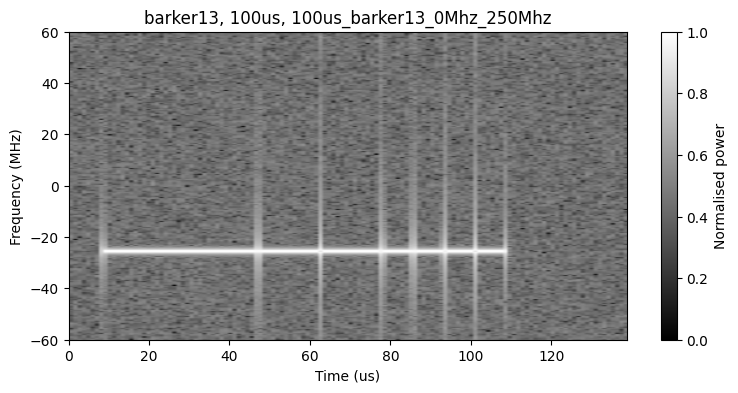

In [5]:
import matplotlib.pyplot as plt
from dataloaders.pulse_dataset import WaveformDataset

def plot_spectrogram(item, fs=WaveformDataset.SAMPLE_RATE):
    """
    Plots one spectrogram item, e.g. plot_spectrogram(train_dataset[0], train_SNRs).
    item: (spectrogram, labels) from the dataset, spectrogram shape (1, frequency, time)
    """
    spec, labels = item

    n_time = spec.shape[-1]
    duration_us = n_time * 128 / fs * 1e6            # hop of 128 samples per time step

    title = f"{labels['waveform']}, {labels['pulse_width']}, {labels['file']}"

    fig, ax = plt.subplots(figsize=(9, 4))
    im = ax.imshow(spec[0].numpy(), origin="lower", aspect="auto", cmap="gray", vmin=0, vmax=1,
                   extent=[0, duration_us, -fs / 2 / 1e6, fs / 2 / 1e6])
    ax.set_title(title)
    ax.set_xlabel("Time (us)")
    ax.set_ylabel("Frequency (MHz)")
    fig.colorbar(im, ax=ax, label="Normalised power")
    plt.show()

plot_spectrogram(train_dataset[0])

## Model

In [6]:
from models.vgg13 import VGG13_net

model = VGG13_net(num_classes=len(waveform_idx))
model = model.to(device)

## Train

In [7]:
import copy
import time
import torch.nn as nn
import torch.optim as optim
from tqdm.auto import tqdm

patience = 15

vgg_epochs = 50
vgg_momentum = 0.9
vgg_learningRate = 1e-4
vgg_weightDecay = 5e-4

criterion = nn.CrossEntropyLoss()
optimiser = optim.SGD(
    model.parameters(),
    lr=vgg_learningRate,
    momentum=vgg_momentum,
    weight_decay=vgg_weightDecay,
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimiser,
    T_max=vgg_epochs,
    eta_min=1e-6   # don't decay all the way to zero
)

best_loss = float("inf")
best_state = None
epochs_no_improve = 0

start_training = time.time()

for epoch in range(vgg_epochs):
    model.train()
    epoch_start = time.time()
    total_train_loss = 0.0

    # Training
    for signals, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{vgg_epochs} - Training", leave=False):
        signals = signals.to(device)
        label_indices = labels["waveform_idx"].to(device)
        preds = model(signals)
        train_loss = criterion(preds, label_indices)
        optimiser.zero_grad()
        train_loss.backward()
        optimiser.step()
        total_train_loss += train_loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    # Evaluation
    model.eval()
    total_test_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for signals, labels in tqdm(test_loader, desc=f"Epoch {epoch+1}/{vgg_epochs} - Testing", leave=False):
            signals = signals.to(device)
            label_indices = labels["waveform_idx"].to(device)
            preds = model(signals)
            test_loss = criterion(preds, label_indices)
            total_test_loss += test_loss.item()
            _, predicted = torch.max(preds, 1)
            total += label_indices.size(0)
            correct += (predicted == label_indices).sum().item()

    avg_test_loss = total_test_loss / len(test_loader)
    accuracy = 100 * correct / total

    scheduler.step()

    print(f"[Epoch {epoch+1}] Train loss: {avg_train_loss:.4f} | Test loss: {avg_test_loss:.4f} | "
          f"Test accuracy: {accuracy:.2f}% | {time.time() - epoch_start:.1f}s")

    # Keep the best model (lowest test loss)
    if avg_test_loss < best_loss:
        best_loss = avg_test_loss
        best_state = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
        print(f"[Epoch {epoch+1}] Best model so far")
    else:
        epochs_no_improve += 1

    # Early stopping
    if epochs_no_improve >= patience:
        print(f"Early stopping triggered after {patience} epochs with no improvement.")
        break

# Continue with the best model, not the last epoch's
model.load_state_dict(best_state)

print(f"Total training time: {(time.time() - start_training) / 60:.2f} minutes")

/home/ryan/anaconda3/envs/RSEI/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[Epoch 1] Train loss: 2.5569 | Test loss: 2.3921 | Test accuracy: 13.64% | 129.7s
[Epoch 1] Best model so far


[Epoch 2] Train loss: 2.2616 | Test loss: 1.8519 | Test accuracy: 36.44% | 139.6s
[Epoch 2] Best model so far


[Epoch 3] Train loss: 1.8457 | Test loss: 1.3742 | Test accuracy: 49.28% | 139.7s
[Epoch 3] Best model so far


[Epoch 4] Train loss: 1.5187 | Test loss: 1.0985 | Test accuracy: 56.05% | 139.6s
[Epoch 4] Best model so far


...

[Epoch 96] Train loss: 0.0314 | Test loss: 0.0062 | Test accuracy: 99.76% | 125.3s


[Epoch 97] Train loss: 0.0314 | Test loss: 0.0055 | Test accuracy: 99.81% | 126.3s


[Epoch 98] Train loss: 0.0325 | Test loss: 0.0065 | Test accuracy: 99.79% | 127.7s


[Epoch 99] Train loss: 0.0316 | Test loss: 0.0066 | Test accuracy: 99.79% | 124.1s


[Epoch 100] Train loss: 0.0318 | Test loss: 0.0061 | Test accuracy: 99.82% | 125.0s
Total training time: 227.18 minutes


## Plotting helpers

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, matthews_corrcoef, f1_score

def plot_confusion_matrix(y_true, y_pred, label):
    mcc = matthews_corrcoef(y_true, y_pred)
    fone = f1_score(y_true, y_pred, average="macro")
    print(f"  [{label}] MCC: {mcc:.4f} | F1 (macro): {fone:.4f}")

    class_ids = sorted(idx_to_label.keys())
    display_labels = [idx_to_label[i] for i in class_ids]
    cm_norm = confusion_matrix(y_true, y_pred, normalize="true", labels=class_ids)

    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=display_labels).plot(
        cmap="viridis", ax=ax, xticks_rotation=45, values_format=".2f"
    )
    ax.set_title(f"Confusion Matrix — {label}", fontsize=14)
    ax.set_xlabel("Predicted Label", fontsize=13)
    ax.set_ylabel("True Label", fontsize=13)
    plt.tight_layout()
    plt.show()

    return mcc, fone


def plot_f1_vs_snr(f1_scores, snrs):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(snrs, f1_scores, marker="o", color="steelblue", linewidth=2, label="VGG13")
    ax.set_xticks(snrs)
    ax.set_xlabel("SNR (dB)", fontsize=13)
    ax.set_ylabel("F1 (macro)", fontsize=13)
    ax.set_ylim(0, 1.05)
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.set_title("F1 vs SNR", fontsize=14)
    plt.tight_layout()
    plt.show()

## Save the model

In [9]:
import os

run_name = "adc0_all_waveforms_vgg13_spectrogram"
run_dir = os.path.join("runs", run_name)
os.makedirs(run_dir, exist_ok=True)

model_path = os.path.join(run_dir, f"{run_name}_model.pth")
torch.save({"model_state_dict": model.state_dict(), "waveform_idx": waveform_idx}, model_path)
print(f"Saved model: {model_path}")
del model, waveform_idx, idx_to_label


Saved model: runs/adc0_all_waveforms_vgg13_spectrogram/adc0_all_waveforms_vgg13_spectrogram_model.pth


## Reload the model

The trained model is deleted from memory and rebuilt from the file, so the evaluation below can only use the reloaded model.

In [9]:
import os

run_name = "adc0_all_waveforms_vgg13_spectrogram"
run_dir = os.path.join("runs", run_name)
os.makedirs(run_dir, exist_ok=True)

model_path = os.path.join(run_dir, f"{run_name}_model.pth")

checkpoint = torch.load(model_path, map_location=device)
waveform_idx = checkpoint["waveform_idx"]
idx_to_label = {v: k for k, v in waveform_idx.items()}

model = VGG13_net(num_classes=len(waveform_idx))
model = model.to(device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print(f"Reloaded model from {model_path}")

Reloaded model from runs/adc0_all_waveforms_vgg13_spectrogram/adc0_all_waveforms_vgg13_spectrogram_model.pth


## Evaluate across the SNR sweep

In [10]:
def predict(loader):
    """Runs the model over a DataLoader and returns the true and predicted waveform class indices."""
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for signals, labels in loader:
            preds = model(signals.to(device))
            y_pred.append(preds.argmax(dim=1).cpu().numpy())
            y_true.append(labels["waveform_idx"].numpy())
    return np.concatenate(y_true), np.concatenate(y_pred)

Evaluating: 15dB
  [15dB] MCC: 1.0000 | F1 (macro): 1.0000


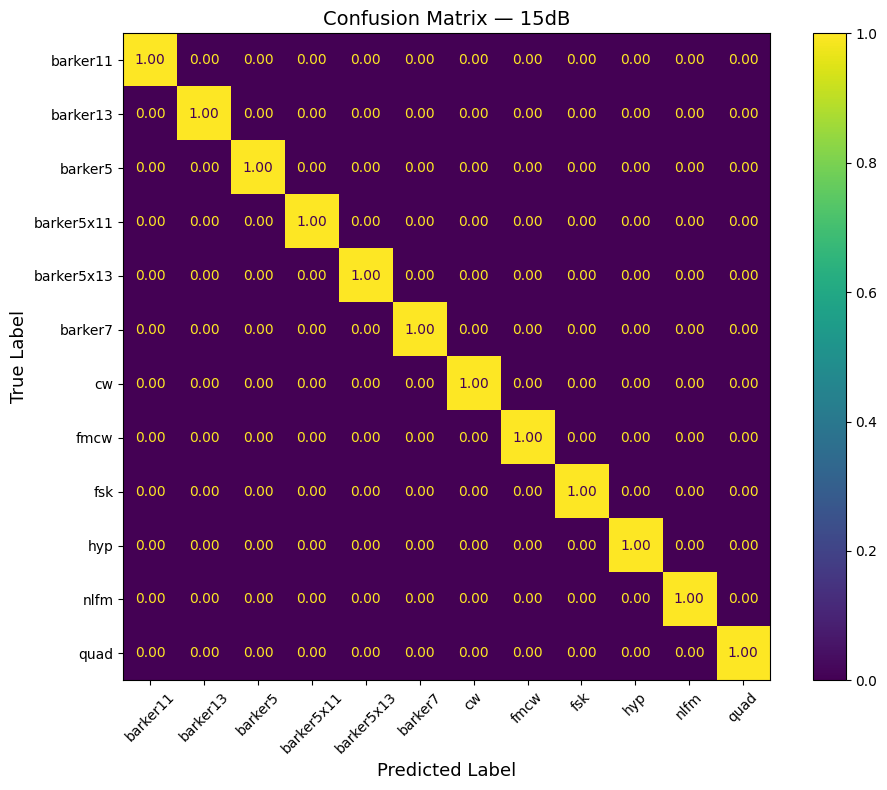

Evaluating: 10dB
  [10dB] MCC: 1.0000 | F1 (macro): 1.0000


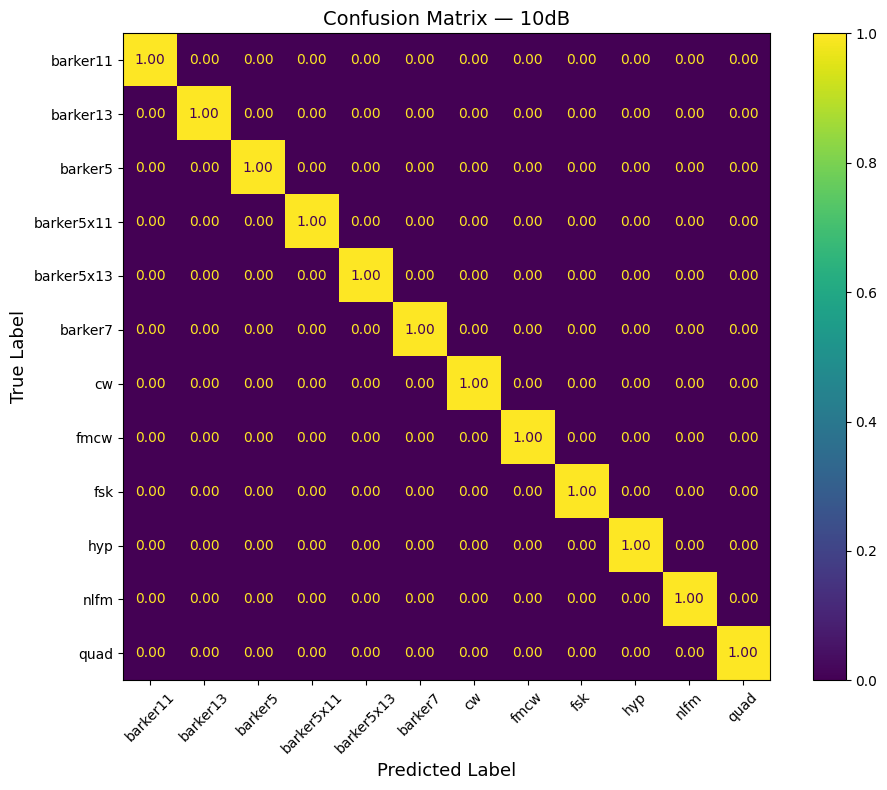

Evaluating: 5dB
  [5dB] MCC: 0.9995 | F1 (macro): 0.9996


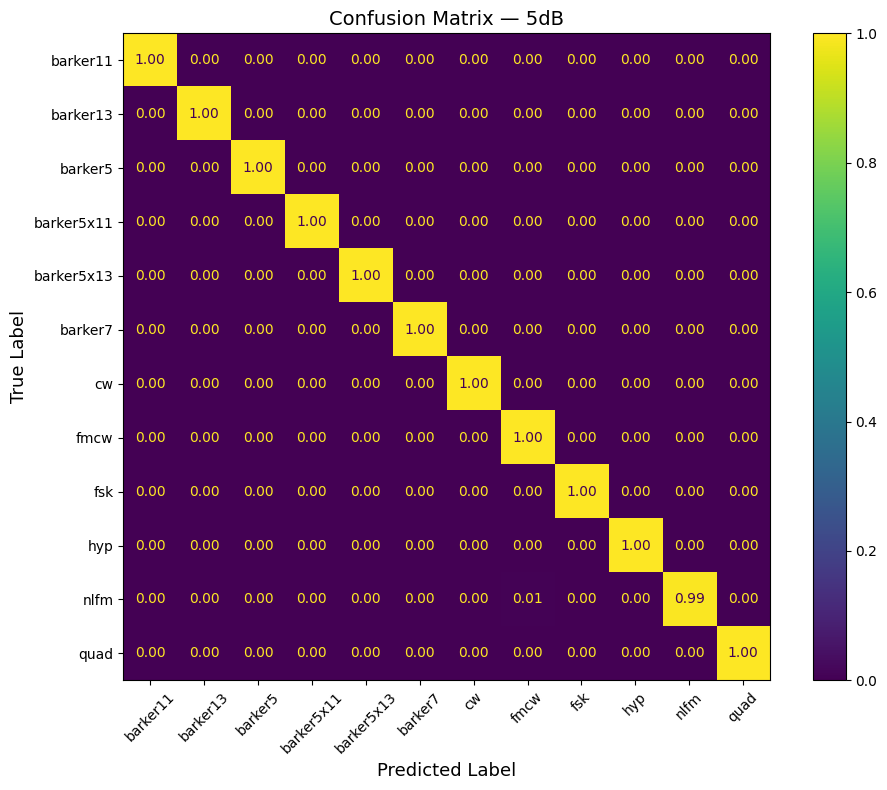

Evaluating: 0dB
  [0dB] MCC: 0.9841 | F1 (macro): 0.9854


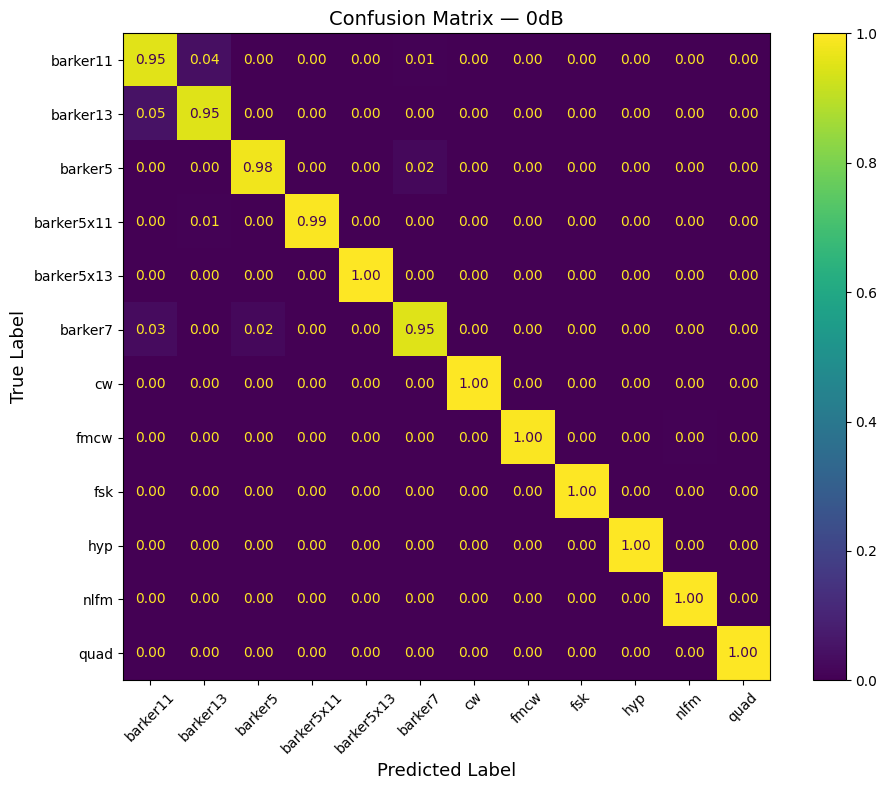

Evaluating: -5dB
  [-5dB] MCC: 0.7432 | F1 (macro): 0.7682


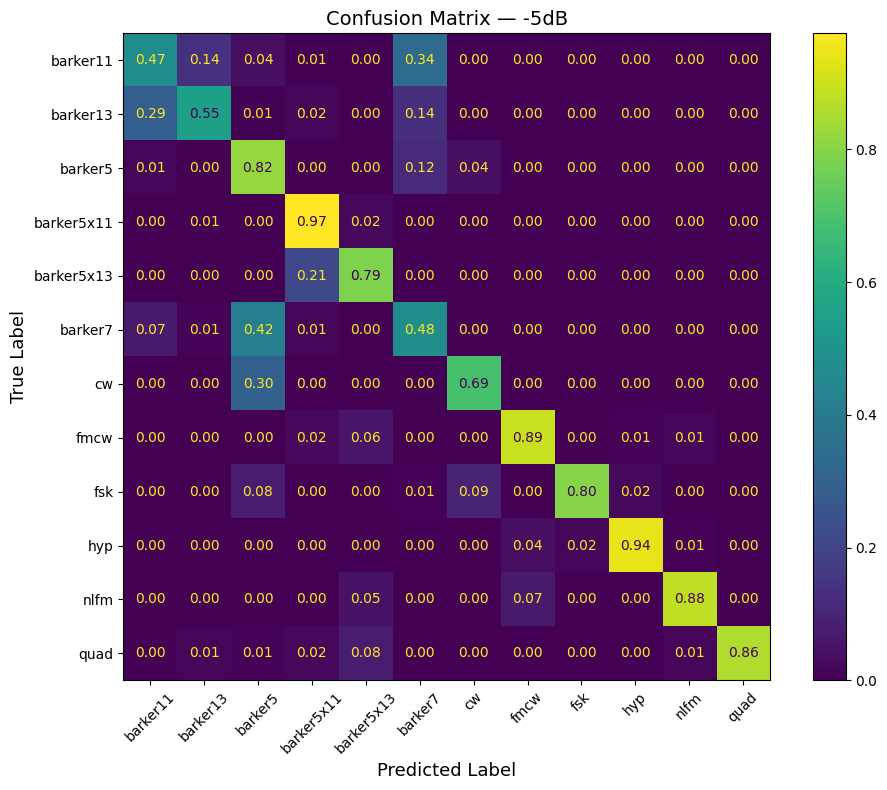

Evaluating: -10dB
  [-10dB] MCC: 0.0955 | F1 (macro): 0.1143


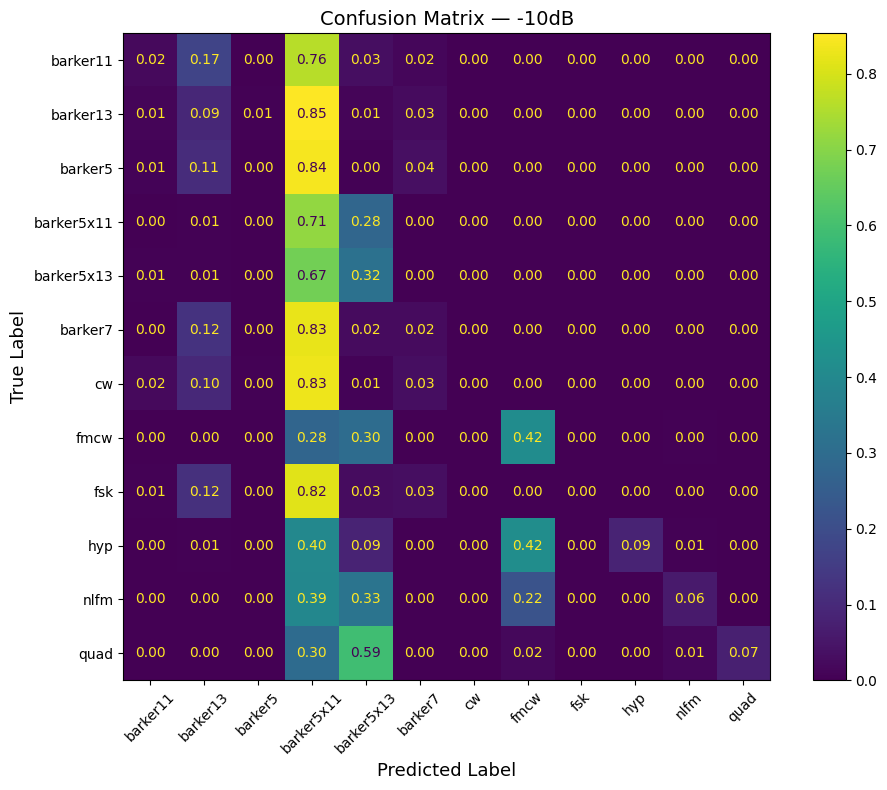

Evaluating: -15dB
  [-15dB] MCC: -0.0022 | F1 (macro): 0.0219


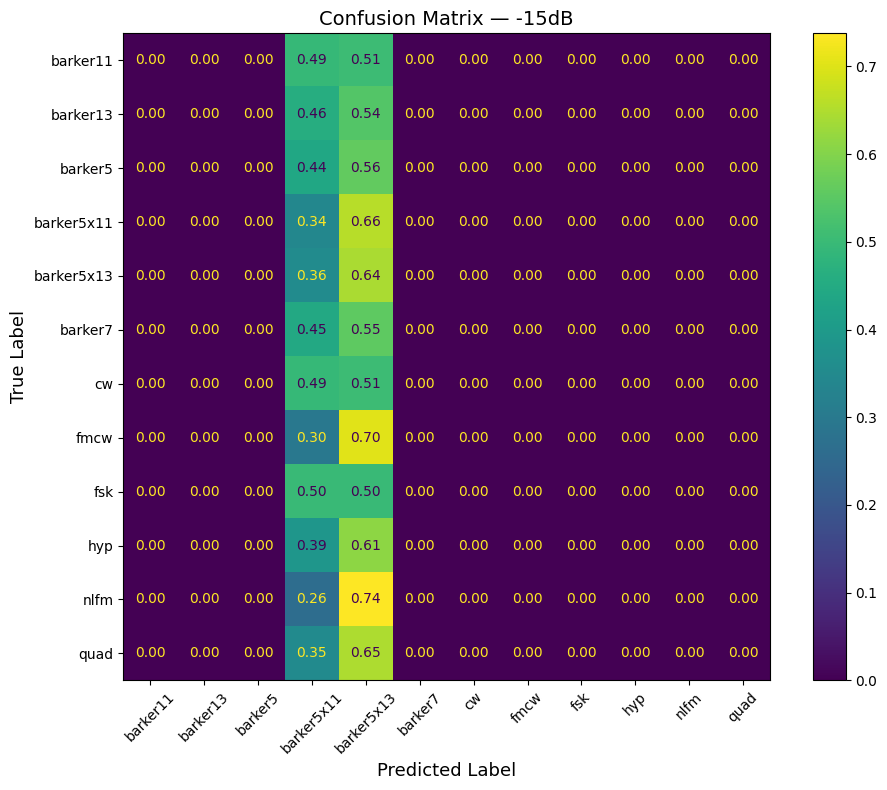

In [11]:
f1_scores = []
val_SNRs = [15, 10, 5, 0, -5, -10, -15]

for snr in val_SNRs:
    label = f"{snr}dB"
    print(f"Evaluating: {label}")

    eval_dataset = AugmentedWaveformDataset(
        base_dataset=test_base,
        target_snrs_db=[snr],
        mode="single",
        transform=Spectrogram(),
    )
    eval_loader = DataLoader(eval_dataset, batch_size=vgg_batchSize, shuffle=False, num_workers=4)

    y_eval, y_pred = predict(eval_loader)

    _, fone = plot_confusion_matrix(y_eval, y_pred, label)
    f1_scores.append(fone)

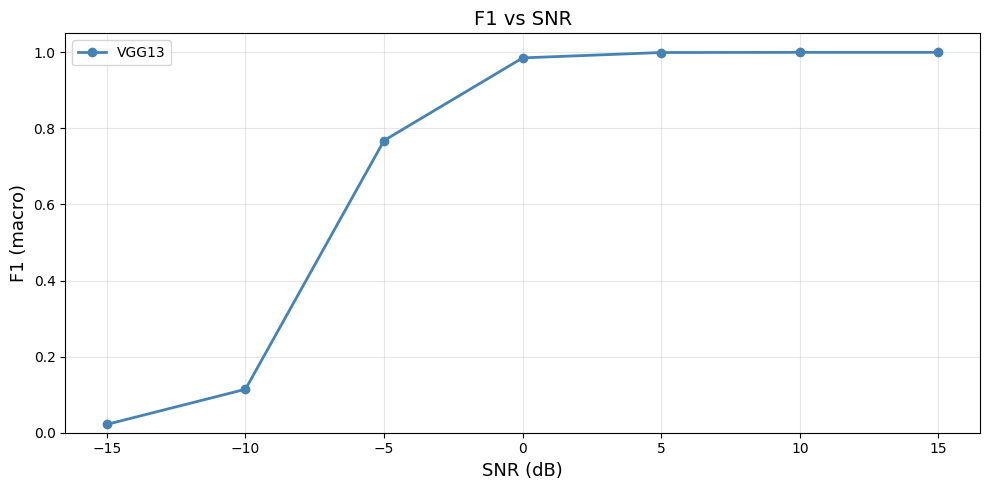

In [13]:
plot_f1_vs_snr(f1_scores, val_SNRs)